# #23J — Darwinian Selection: Which Ingredient Is Actually Necessary?

Darwin's argument needs three things at once: heritable variation in a trait, a real link between that
trait and reproductive success, and transmission of the trait to offspring. This notebook builds a minimal
individual-based simulation and tests each ingredient's necessity directly, by removing exactly one at a
time and watching whether the population's trait distribution still shifts.

Read `PROJECT_NARRATIVE.md` and `WORKFLOW.md` before starting. Blanks (`____`) are yours to fill from the
hint comment + the library docs — don't just copy the hint text verbatim, understand what it's doing first.

## Step 0 — Setup

Pure boilerplate: imports and the results directory. Nothing to learn here.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import os

os.makedirs("results", exist_ok=True)
np.set_printoptions(precision=4, suppress=True)
print("Setup complete.")

Setup complete.


## Step 1 — The fitness-trait link: a logistic survival function

**Biology:** an individual's trait value `z` determines its probability of surviving to reproduce. We want
a *smooth* function of `z` that stays inside `[0, 1]` without ever needing to be clipped — a hard linear
cutoff would create artificial flat zones exactly at the trait extremes where the real strength of the
fitness-trait link matters most.

**Math:** the logistic function `p(z) = 1 / (1 + exp(-slope * (z - midpoint)))`. At `z = midpoint`,
`p = 0.5`. As `slope` increases, the curve gets steeper. Setting `slope = 0` makes `p` constant at `0.5` for
every `z`, regardless of trait value — this is exactly how the "zero fitness differential" ablation will
work later: survival becomes literally independent of trait.


In [19]:
def logistic_survival(z, midpoint, slope):
    """Return survival probability for each trait value in z (array)."""
    p = 1.0/(1.0 + np.exp(-slope*(z - midpoint)))
    return p

test_z = np.array([-2.0, 0.0, 2.0])
print("slope=1.5:", logistic_survival(test_z, 0.0, 1.5))
print("slope=0.0:", logistic_survival(test_z, 0.0, 0.0))

slope=1.5: [0.0474 0.5    0.9526]
slope=0.0: [0.5 0.5 0.5]


## Step 2 — One generation: selection, then reproduction

**Biology:** each generation has two steps. *Selection*: each individual survives or not as a real
probabilistic (Bernoulli) outcome of its own survival probability, not a deterministic cutoff. *Reproduction*:
each offspring is produced by picking a random surviving parent and blending the parent's trait value with
the **current generation's own pre-selection population mean**, weighted by heritability `h2`.

**Math — parent-offspring regression:** `z_offspring = mu_pre + h2 * (z_parent - mu_pre) + noise`, where
`mu_pre` is *this* generation's own pre-selection mean. At `h2=1`, offspring trait equals parent trait
(mod noise) — the mean can drift generation after generation. At `h2=0`, offspring always regresses fully
back to `mu_pre` — no inheritance, the mean can never shift. (Using a *fixed ancestral* mean here instead of
the current generation's own mean would be a subtle bug: it would permanently pull every future generation
back toward generation 0, making cumulative drift impossible even at `h2=1` — worth understanding why that's
wrong before writing this.)


In [20]:
def one_generation(z, midpoint, slope, h2, sigma_e, rng):
    """One generation: logistic selection, then heritability-weighted reproduction back to len(z)."""
    N = len(z)
    mu_pre = z.mean()
    p_surv = logistic_survival(z, midpoint, slope)
    survive = rng.random(N) < p_surv
    survivors = z[survive]
    if len(survivors) < 2:
        survivors = rng.choice(z, size=max(2, N // 10), replace = True)
    parent_idx = rng.integers(0, len(survivors), size=N)
    parent_vals = survivors[parent_idx]
    noise = rng.normal(0, sigma_e, size=N)
    z_next = mu_pre + h2 * (parent_vals - mu_pre) + noise
    return z_next

rng_test = np.random.default_rng(0)
z_test = rng_test.normal(0, 1, 10)
z_next_test = one_generation(z_test, 0.0, 1.5, 0.5, 0.05, rng_test)
print("before:", z_test.round(2))
print("after :", z_next_test.round(2))
assert len(z_next_test) == len(z_test), "population size must stay constant"
print("Shape check passed.")

before: [ 0.13 -0.13  0.64  0.1  -0.54  0.36  1.3   0.95 -0.7  -1.27]
after : [ 0.23 -0.06 -0.07 -0.05 -0.01  0.64  0.21  0.69  0.12  0.71]
Shape check passed.


## Step 3 — Running the model across many generations

Wrap `one_generation` in a loop, tracking the population's trait mean *and* variance (you'll need variance
again in Step 8) every generation, starting from `N` individuals drawn from `Normal(midpoint, sigma0)`.

Write `run_model(N, generations, sigma0, h2, slope, midpoint, sigma_e, seed)` returning `(means, variances)`
as arrays of length `generations + 1` (including the starting generation).

In [21]:
def run_model(N, generations, sigma0, h2, slope, midpoint, sigma_e, seed):
    rng = np.random.default_rng(seed)
    z = rng.normal(loc=midpoint, scale=sigma0, size=N)
    means = [z.mean()]
    variances = [z.var()]
    for g in range(generations):
        z = one_generation(z, midpoint, slope, h2, sigma_e, rng)
        means.append(z.mean())
        variances.append(z.var())
    return np.array(means), np.array(variances)

m_test, v_test = run_model(N=500, generations=5, sigma0=1.0, h2=0.5, slope=1.5, midpoint=0.0, sigma_e=0.05, seed=1)
print("means:", m_test.round(3))
print("variances:", v_test.round(3))

means: [-0.036  0.19   0.22   0.23   0.233  0.236]
variances: [0.833 0.163 0.042 0.012 0.006 0.004]


## Step 4 — The full condition, across multiple replicate seeds

A single random seed can look directional purely by chance (finite-population sampling noise). Run the full
condition — all three ingredients present — across **30 replicate seeds**, each for **40 generations**, with
`N=2000, sigma0=1.0, h2=0.5, slope=1.5, midpoint=0.0, sigma_e=0.05`. For each replicate, fit a linear
regression of trait mean vs. generation number and record the slope and p-value. Report the fraction of replicates with a significant (`p<0.05`) *positive* slope, and the mean slope
across all 30.

**A subtlety worth knowing before you interpret these numbers:** a trait-mean trajectory where each
generation's value depends on the previous one (which is exactly what's happening here, even under a true
null) behaves somewhat like a random walk — and regressing a random walk against time tends to find
"significant" trends far more often than the nominal 5% false-positive rate, because consecutive points
aren't independent the way simple linear regression assumes. This means "is any single replicate's slope
significant" is not, on its own, a trustworthy sign of a real directional response — you'll see this matter
directly in Step 5.


In [22]:
N, GENERATIONS = 2000, 40
SIGMA0, H2_FULL, SLOPE, MIDPOINT, SIGMA_E = 1.0, 0.5, 1.5, 0.0, 0.05
N_REPLICATES = 30

def run_replicates(sigma0, h2, slope, sigma_e, n_reps=N_REPLICATES, generations=GENERATIONS, N=N):
    """Run n_reps independent replicates; return a list of dicts with means/variances/slope/pvalue."""
    results = []
    for seed in range(n_reps):
        means, variances = run_model(N, generations, sigma0, h2, slope, MIDPOINT, sigma_e, seed)
        gens = np.arange(len(means))
        slope_fit, intercept, r, pvalue, se = stats.linregress(gens, means)
        results.append({"means": means, "variances": variances, "slope": slope_fit, "pvalue": pvalue})
    return results

full_results = run_replicates(SIGMA0, H2_FULL, SLOPE, SIGMA_E)
full_slopes = np.array([r["slope"] for r in full_results])
full_pvals = np.array([r["pvalue"] for r in full_results])
frac_significant_positive = np.mean((full_pvals < 0.05) & (full_slopes > 0))
print(f"FULL condition: mean slope = {full_slopes.mean():.5f}, "
      f"fraction significant+positive = {frac_significant_positive:.2f}")

FULL condition: mean slope = 0.00240, fraction significant+positive = 1.00


## Step 5 — The three ablations

Each ablation removes exactly one ingredient, holding the other parameters at the full condition's values.

- **Ablation A — zero variance.** `sigma0 = 0`. **Also set `sigma_e = 0`** — if environmental noise is left
  on, it quietly reintroduces a trickle of new variance every generation, and since `h2 > 0`, part of that
  noise-induced variance *is* heritable — so a "zero starting variance" ablation with noise left on isn't
  actually a clean null; it slowly accumulates a small but real, statistically detectable response given
  enough generations. With `sigma_e = 0` too, this ablation should be an *exact* null (flat to machine
  precision, not just "roughly flat") — verify that yourself below.
- **Ablation B — zero fitness differential.** `slope = 0` (recall Step 1's sanity check: constant p=0.5).
- **Ablation C — zero heritability.** `h2 = 0`.

Following on from Step 4's subtlety: for each ablation, report *two* separate fractions — the fraction of
replicates significant **and positive**, and the fraction significant **and negative** — rather than one
lumped "any-direction significant" number. A real directional response shows up as one of those two
fractions being large and the other near zero (like the full condition in Step 4). A spurious,
autocorrelation-inflated "significance" with no real underlying bias shows up as the two fractions being
roughly *equal* to each other, even if each one individually looks alarmingly large — that even split is the
real tell that nothing directional is actually happening.

In [23]:
ablation_A = run_replicates(sigma0=0.0, h2=H2_FULL, slope=SLOPE, sigma_e= 0.0)
ablation_B = run_replicates(sigma0=SIGMA0, h2=H2_FULL, slope= 0.0, sigma_e=SIGMA_E)
ablation_C = run_replicates(sigma0=SIGMA0, h2= 0.0, slope=SLOPE, sigma_e=SIGMA_E)

for name, results in [("A (zero variance)", ablation_A), ("B (zero fitness diff)", ablation_B),
                       ("C (zero heritability)", ablation_C)]:
    slopes = np.array([r["slope"] for r in results])
    pvals = np.array([r["pvalue"] for r in results])
    frac_sig_pos = np.mean((pvals < 0.05) & (slopes > 0))
    frac_sig_neg = np.mean((pvals < 0.05) & (slopes < 0 ))
    print(f"Ablation {name}: mean slope = {slopes.mean():.7f}, "
          f"frac significant+positive = {frac_sig_pos:.2f}, frac significant+negative = {frac_sig_neg:.2f}")

a_first_rep_means = ablation_A[0]["means"]
print("\nAblation A single replicate, first vs last generation (should be identical):",
      a_first_rep_means[0], "->", a_first_rep_means[-1])

Ablation A (zero variance): mean slope = 0.0000000, frac significant+positive = 0.00, frac significant+negative = 0.00
Ablation B (zero fitness diff): mean slope = 0.0000073, frac significant+positive = 0.33, frac significant+negative = 0.37
Ablation C (zero heritability): mean slope = 0.0000432, frac significant+positive = 0.40, frac significant+negative = 0.33

Ablation A single replicate, first vs last generation (should be identical): 0.0 -> 0.0


## Step 6 — The hero figure: full condition vs. the three ablations

A 2x2 grid: full condition, ablation A, ablation B, ablation C. In each panel, plot every replicate's
trajectory as a thin semi-transparent line, plus the across-replicate average as a bold line. Use a shared
y-axis range across all four panels so the visual contrast is honest, not an axis-scaling artifact.


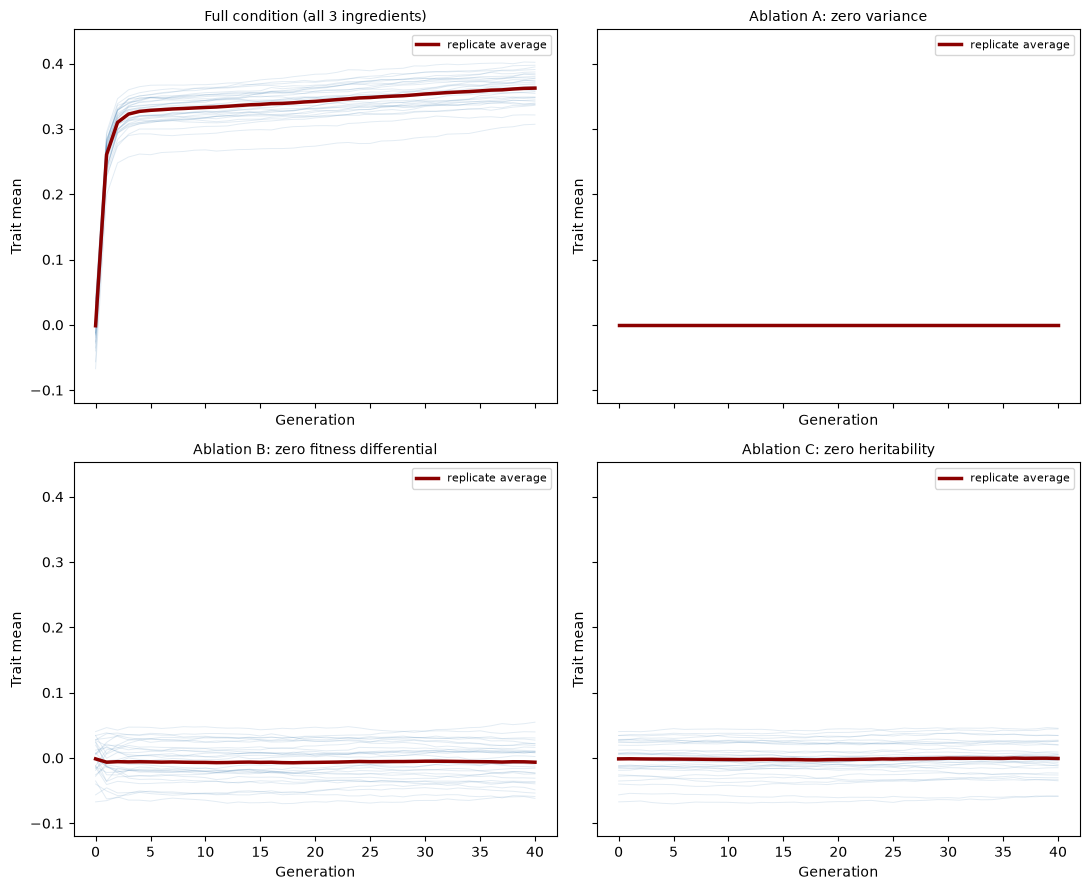

Saved results/hero_ablations.png


In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
panel_data = [("Full condition (all 3 ingredients)", full_results),
              ("Ablation A: zero variance", ablation_A),
              ("Ablation B: zero fitness differential", ablation_B),
              ("Ablation C: zero heritability", ablation_C)]

all_means_stacked = []
for ax, (title, results) in zip(axes.flat, panel_data):
    stacked = np.stack([r["means"] for r in results])
    all_means_stacked.append(stacked)
    for row in stacked:
        ax.plot(row, color="steelblue", alpha= 0.15, linewidth=0.7)
    avg_trajectory = stacked.mean(axis=0)
    ax.plot(avg_trajectory, color="darkred", linewidth=2.5, label="replicate average")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Generation")
    ax.set_ylabel("Trait mean")
    ax.legend(fontsize=8)

y_all = np.concatenate([s.ravel() for s in all_means_stacked])
for ax in axes.flat:
    ax.set_ylim(y_all.min() - 0.05, y_all.max()+ 0.05)

plt.tight_layout()
plt.savefig("results/hero_ablations.png", dpi=150)
plt.show()
print("Saved results/hero_ablations.png")

## Step 7 — The breeder's equation, checked against one real generation

Run a single fresh generation of the full condition and directly compute:

- `S` (selection differential) = mean trait of survivors minus the pre-selection population mean.
- The actual response `R` = next generation's mean minus the same pre-selection mean.
- The breeder's-equation prediction: `h2 * S`.

In [25]:
rng_breed = np.random.default_rng(7)
z0 = rng_breed.normal(MIDPOINT, SIGMA0, N)
mu_pre = z0.mean()
p_surv0 = logistic_survival(z0, MIDPOINT, SLOPE)
survive0 = rng_breed.random(N) < p_surv0
survivors0 = z0[survive0]

S = survivors0.mean() - mu_pre
z1 = one_generation(z0, MIDPOINT, SLOPE, H2_FULL, SIGMA_E, rng_breed)
# NOTE: one_generation draws its own fresh selection internally, so this re-selects — fine for this
# single-generation demonstration since we only need one real R, not a matched-selection comparison.
R_actual = z1.mean() - mu_pre
R_predicted = H2_FULL * S

rel_error = abs(R_actual - R_predicted)/abs(R_predicted)
print(f"S (selection differential)   = {S:.5f}")
print(f"Predicted R = h2*S            = {R_predicted:.5f}")
print(f"Actual R                     = {R_actual:.5f}")
print(f"Relative error                = {rel_error:.2%}")

S (selection differential)   = 0.55172
Predicted R = h2*S            = 0.27586
Actual R                     = 0.26889
Relative error                = 2.53%


## Step 8 — The heritability sweep: single-generation accuracy vs. multi-generation breakdown

Sweep `h2` continuously across 11 values from 0.0 to 1.0. For each value, holding `sigma0`, `slope`, `sigma_e`
at their full-condition values:

1. Run **one single generation** (matched selection, like Step 7) and record the actual `R` vs. predicted
   `h2*S`.
2. Separately, run the **full 15-generation simulation** (5 replicate seeds, averaged) and record the real
   cumulative response (`final mean - initial mean`), the final/initial variance ratio, and the *naive*
   linear extrapolation `generations * h2 * S0` for comparison.

The single-generation check should match well for every `h2`. The multi-generation comparison is expected to
diverge from the naive extrapolation — *why* it diverges is worth understanding before moving on: re-read
PROJECT_NARRATIVE.md Section 6 if the shape of the divergence doesn't make sense once you see it.

In [26]:
h2_grid = np.linspace(0.0, 1.0, 11)
sweep_generations = 15
sweep_reps = 5

rng_s0 = np.random.default_rng(999)
z_s0 = rng_s0.normal(MIDPOINT, SIGMA0, N)
surv_s0 = rng_s0.random(N) < logistic_survival(z_s0, MIDPOINT, SLOPE)
S0 = z_s0[surv_s0].mean() - z_s0.mean()

rows = []
for h2 in h2_grid:
    rng_single = np.random.default_rng(123)
    z_a = rng_single.normal(MIDPOINT, SIGMA0, N)
    mu_pre_single = z_a.mean()
    surv_a = rng_single.random(N) < logistic_survival(z_a, MIDPOINT, SLOPE)
    S_single = z_a[surv_a].mean() - mu_pre_single
    z_b = one_generation(z_a, MIDPOINT, SLOPE, h2, SIGMA_E, rng_single)
    R_single_actual = z_b.mean() - mu_pre_single
    R_single_predicted = h2 * S_single

    cum_Rs, var_ratios = [], []
    for seed in range(sweep_reps):
        means, variances = run_model(N, sweep_generations, SIGMA0, h2, SLOPE, MIDPOINT, SIGMA_E, seed)
        cum_Rs.append(means[-1] - means[0])
        var_ratios.append(variances[-1]/variances[0] if variances[0] > 0 else np.nan)
    cum_R_actual = np.mean(cum_Rs)
    var_ratio = np.nanmean(var_ratios)
    naive_cum_R = sweep_generations * h2 *S0

    rows.append({"h2": h2, "R_single_actual": R_single_actual, "R_single_predicted": R_single_predicted,
                 "cum_R_actual": cum_R_actual, "naive_cum_R": naive_cum_R, "var_ratio": var_ratio})

sweep_df = pd.DataFrame(rows)
sweep_df.to_csv("results/heritability_sweep.csv", index=False)
sweep_df

,h2,R_single_actual,R_single_predicted,cum_R_actual,naive_cum_R,var_ratio
0,0.0,-0.000604,0.000000,-0.004060,0.000000,0.002531
1,0.1,0.053661,0.053914,0.051601,0.749329,0.002557
2,0.2,0.107926,0.107827,0.109465,1.498659,0.002631
3,0.3,0.162192,0.161741,0.174084,2.247988,0.002773
4,0.4,0.216457,0.215654,0.248287,2.997318,0.003043
5,0.5,0.270722,0.269568,0.334798,3.746647,0.003379
6,0.6,0.324987,0.323481,0.456935,4.495976,0.003916
7,0.7,0.379253,0.377395,0.587663,5.245306,0.004963
8,0.8,0.433518,0.431308,0.817376,5.994635,0.007394
9,0.9,0.487783,0.485222,1.167368,6.743965,0.030861


## Step 9 — Visualizing the sweep: single-gen accuracy vs. multi-gen divergence

Two side-by-side panels: left, predicted vs. actual single-generation response across the `h2` grid (should
track closely); right, actual cumulative multi-generation response vs. the naive linear extrapolation
(expected to diverge, especially at high `h2`).

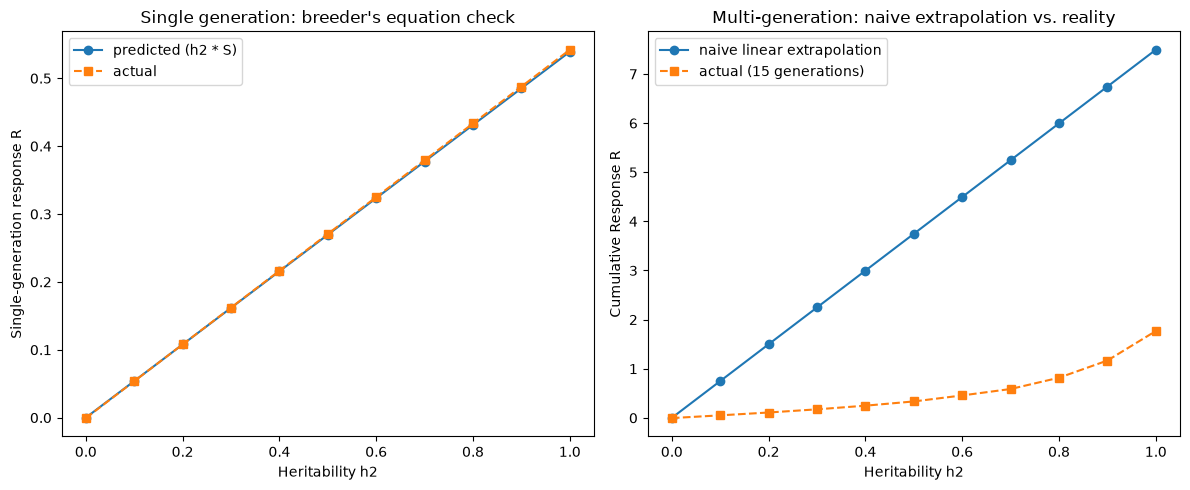

Saved results/heritability_sweep.png


In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(sweep_df["h2"], sweep_df["R_single_predicted"], "o-", label="predicted (h2 * S)")
ax1.plot(sweep_df["h2"], sweep_df["R_single_actual"], "s--", label="actual")
ax1.set_xlabel("Heritability h2")
ax1.set_ylabel("Single-generation response R")
ax1.set_title("Single generation: breeder's equation check")
ax1.legend()

ax2.plot(sweep_df["h2"], sweep_df["naive_cum_R"], "o-", label="naive linear extrapolation")
ax2.plot(sweep_df["h2"], sweep_df["cum_R_actual"], "s--", label="actual (15 generations)")
ax2.set_xlabel("Heritability h2")
ax2.set_ylabel("Cumulative Response R")
ax2.set_title("Multi-generation: naive extrapolation vs. reality")
ax2.legend()

plt.tight_layout()
plt.savefig("results/heritability_sweep.png", dpi=150)
plt.show()
print("Saved results/heritability_sweep.png")

## Step 10 — Export summary CSVs and print the final interpretation checklist

Pure export/bookkeeping — collects everything into tidy CSVs for the README/results folder.

In [28]:
summary_rows = []
for name, results in [("full", full_results), ("ablation_A_zero_variance", ablation_A),
                       ("ablation_B_zero_fitness_diff", ablation_B), ("ablation_C_zero_heritability", ablation_C)]:
    slopes = np.array([r["slope"] for r in results])
    pvals = np.array([r["pvalue"] for r in results])
    summary_rows.append({
        "condition": name,
        "mean_slope": slopes.mean(),
        "frac_significant_positive": np.mean((pvals < 0.05) & (slopes > 0)),
        "frac_significant_negative": np.mean((pvals < 0.05) & (slopes < 0)),
        "mean_total_shift": np.mean([r["means"][-1] - r["means"][0] for r in results]),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("results/ablation_summary.csv", index=False)

print("=" * 70)
print("ABLATION SUMMARY")
print(summary_df.to_string(index=False))
print("=" * 70)
print(f"\nBreeder's equation single-generation check: predicted {R_predicted:.5f} vs actual {R_actual:.5f} "
      f"({rel_error:.2%} relative error)")
print("\nFull results saved to results/: hero_ablations.png, heritability_sweep.png,")
print("heritability_sweep.csv, ablation_summary.csv")

ABLATION SUMMARY
                   condition  mean_slope  frac_significant_positive  frac_significant_negative  mean_total_shift
                        full    0.002401                   1.000000                   0.000000          0.363778
    ablation_A_zero_variance    0.000000                   0.000000                   0.000000          0.000000
ablation_B_zero_fitness_diff    0.000007                   0.333333                   0.366667         -0.005088
ablation_C_zero_heritability    0.000043                   0.400000                   0.333333          0.000644

Breeder's equation single-generation check: predicted 0.27586 vs actual 0.26889 (2.53% relative error)

Full results saved to results/: hero_ablations.png, heritability_sweep.png,
heritability_sweep.csv, ablation_summary.csv
